# 03 · Baselines, diagnostic biais–variance et méthodes d'ensemble

**Étapes 5–6** du cas pratique · Slides 9–15, 21, 24, 31–38.

Toutes les évaluations utilisent le protocole de l'étape 4 : `load_split()` (le test reste scellé), le même objet `CV` (5 plis stratifiés) et les mêmes métriques (`SCORING`).

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, learning_curve, validation_curve

from financial_inclusion_africa import config, viz
from financial_inclusion_africa.data import load_split
from financial_inclusion_africa.evaluate import (
    CV, T_STAR, evaluate_cv, fold_scores, format_summary, full_classification_report,
    one_standard_error, paired_difference,
)
from financial_inclusion_africa.features import pipe

viz.set_style()
pd.set_option("display.max_columns", 30)
X_train, X_test, y_train, y_test = load_split()  # X_test, y_test : non utilisés avant l'étape 10
print(f"X_train : {len(X_train):,} lignes · {y_train.mean():.2%} de positifs")

X_train : 18,819 lignes · 14.08% de positifs


## Étape 5 · Baselines et diagnostic biais–variance

### 5.1 Trois modèles de référence

| Rôle | Modèle | Préparation |
|---|---|---|
| Plancher | `DummyClassifier(strategy="most_frequent")` | aucune |
| **Modèle de base** | `LogisticRegression(max_iter=2000)` | `pipe(..., features=...)` : colonnes brutes (`"none"`), variables du guide (`"guide"`), guide + nos variables (`"all"`) |
| Modèle flexible | `RandomForestClassifier(n_estimators=300)`, réglages par défaut | `pipe(..., scale=False)` : one-hot, sans standardisation (inutile pour les arbres, Q3.4) |

Les forêts sont entraînées sur un seul cœur (`n_jobs=1`) : c'est la validation croisée qui parallélise les plis. Paralléliser aux deux niveaux n'accélère rien et produit des avertissements de joblib.

In [2]:
models = {
    "plancher (most_frequent)": DummyClassifier(strategy="most_frequent"),
    "régression logistique · colonnes brutes": pipe(LogisticRegression(max_iter=2000), features="none"),
    "régression logistique · variables du guide": pipe(LogisticRegression(max_iter=2000), features="guide"),
    "régression logistique · guide + nos variables": pipe(LogisticRegression(max_iter=2000), features="all"),
    "forêt aléatoire (défaut)": pipe(RandomForestClassifier(n_estimators=300,
                                                           random_state=config.RANDOM_STATE), scale=False),
}
rows, results = [], {}
for name, model in models.items():
    row, results[name] = evaluate_cv(model, X_train, y_train, name=name)
    rows.append(row)
summary = pd.DataFrame(rows)

### Q5.1 · Tableau des trois modèles

In [3]:
print("Validation croisée (5 plis) · moyenne ± écart-type")
format_summary(summary, metrics=["pr_auc", "roc_auc", "brier", "acc", "logloss", "precision_t", "recall_t", "cost_t"])

Validation croisée (5 plis) · moyenne ± écart-type


,pr_auc,roc_auc,brier,acc,logloss,precision_t,recall_t,cost_t,temps (s)
plancher (most_frequent),0.141 ± 0.000,0.500 ± 0.000,0.141 ± 0.000,0.859 ± 0.000,5.075 ± 0.001,0.000 ± 0.000,0.000 ± 0.000,0.704 ± 0.000,0.02
régression logistique · colonnes brutes,0.559 ± 0.027,0.848 ± 0.010,0.087 ± 0.003,0.884 ± 0.004,0.293 ± 0.009,0.276 ± 0.005,0.857 ± 0.010,0.259 ± 0.007,0.18
régression logistique · variables du guide,0.561 ± 0.026,0.849 ± 0.010,0.087 ± 0.003,0.885 ± 0.005,0.292 ± 0.009,0.279 ± 0.005,0.854 ± 0.010,0.258 ± 0.006,0.21
régression logistique · guide + nos variables,0.561 ± 0.026,0.849 ± 0.010,0.087 ± 0.003,0.885 ± 0.005,0.292 ± 0.009,0.279 ± 0.004,0.852 ± 0.011,0.259 ± 0.006,0.22
forêt aléatoire (défaut),0.475 ± 0.034,0.804 ± 0.010,0.103 ± 0.004,0.863 ± 0.007,0.573 ± 0.038,0.303 ± 0.005,0.736 ± 0.011,0.305 ± 0.007,3.61


In [4]:
# Rapport de classification complet au seuil t*, sur les prédictions hors pli (même CV)
for name in ["plancher (most_frequent)", "régression logistique · guide + nos variables", "forêt aléatoire (défaut)"]:
    oof = cross_val_predict(models[name], X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    print(f"── {name} · seuil t* = {T_STAR:.3f}\n{full_classification_report(y_train, oof, T_STAR)}")

── plancher (most_frequent) · seuil t* = 0.091
              precision    recall  f1-score   support

      No (0)     0.8592    1.0000    0.9243     16169
     Yes (1)     0.0000    0.0000    0.0000      2650

    accuracy                         0.8592     18819
   macro avg     0.4296    0.5000    0.4621     18819
weighted avg     0.7382    0.8592    0.7941     18819



── régression logistique · guide + nos variables · seuil t* = 0.091
              precision    recall  f1-score   support

      No (0)     0.9635    0.6386    0.7681     16169
     Yes (1)     0.2788    0.8525    0.4202      2650

    accuracy                         0.6687     18819
   macro avg     0.6212    0.7455    0.5942     18819
weighted avg     0.8671    0.6687    0.7191     18819



── forêt aléatoire (défaut) · seuil t* = 0.091
              precision    recall  f1-score   support

      No (0)     0.9435    0.7228    0.8185     16169
     Yes (1)     0.3032    0.7358    0.4294      2650

    accuracy                         0.7246     18819
   macro avg     0.6233    0.7293    0.6240     18819
weighted avg     0.8533    0.7246    0.7637     18819



**Réponse Q5.1.** (accuracy au seuil 0,5, convention de scikit-learn ; précision, recall et coût au seuil $t^* \approx 0{,}091$)

| Modèle | PR-AUC | ROC-AUC | Brier | Accuracy | Log-loss | Recall à $t^*$ | Coût / pers. | Temps |
|---|---|---|---|---|---|---|---|---|
| Plancher | 0,141 ± 0,000 | 0,500 | 0,141 | 0,859 | 5,075 | 0,000 | 0,70 USD | 0,01 s |
| **Régression logistique** (guide + nos variables) | **0,561 ± 0,026** | 0,849 ± 0,010 | **0,087** | **0,885** | **0,292** | 0,852 | **0,26 USD** | 0,2 s |
| Forêt aléatoire (défaut) | 0,475 ± 0,034 | 0,804 ± 0,010 | 0,103 | 0,863 | 0,573 | 0,736 | 0,31 USD | 3,6 s |

- Le **plancher** a une accuracy de 0,859, presque celle de la forêt (0,863), avec un recall nul et le coût maximal (personne n'est contacté) : l'accuracy seule ne départage rien.
- La **régression logistique** gagne sur **toutes** les métriques, en plus de 10 fois moins de temps que la forêt.
- La **forêt par défaut** est nettement moins bonne : PR-AUC 0,475, log-loss presque double (0,573, des erreurs commises avec certitude), recall à $t^*$ plus faible. Le rapport de classification montre qu'au seuil $t^*$ elle contacte moins de monde (précision un peu meilleure, recall bien plus bas) : ses probabilités sont très concentrées près de 0 et de 1, signe de surapprentissage (Q5.3).

### Q5.2 · Nos nouvelles variables améliorent-elles la régression logistique ?

,moyenne A,moyenne B,écart-type A,différence moyenne B − A,écart-type des différences,erreur-type des différences,plis où B > A,plis
variables du guide − colonnes brutes,0.5587,0.5610,0.0271,0.0024,0.0016,0.0008,5.0,5.0
nos variables (Q3.5) : (guide + nos variables) − guide,0.5610,0.5605,0.0260,-0.0005,0.0011,0.0006,3.0,5.0


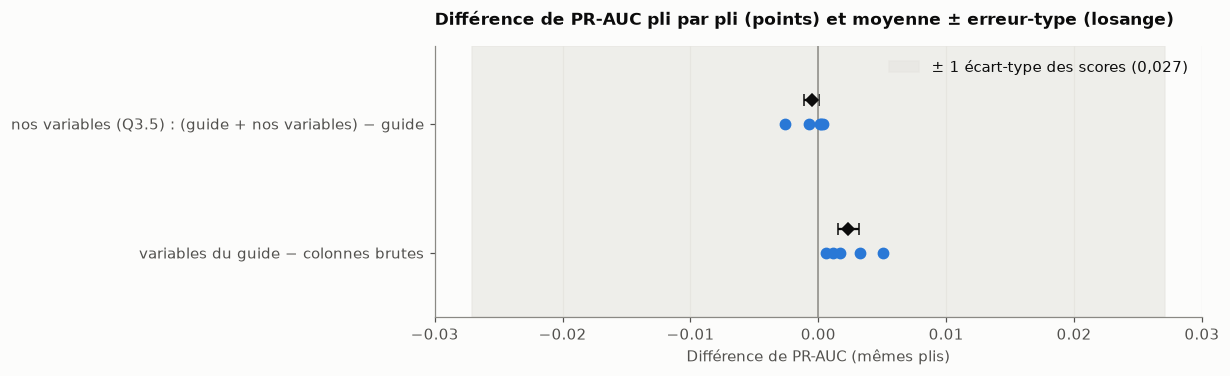

In [5]:
names = {
    "brutes": "régression logistique · colonnes brutes",
    "guide": "régression logistique · variables du guide",
    "guide + nos variables": "régression logistique · guide + nos variables",
}
comparisons = {
    "variables du guide − colonnes brutes": ("brutes", "guide"),
    "nos variables (Q3.5) : (guide + nos variables) − guide": ("guide", "guide + nos variables"),
}
paired = pd.DataFrame({label: paired_difference(results[names[a]], results[names[b]])
                       for label, (a, b) in comparisons.items()}).T
display(paired.round(4))

fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (label, (a, b)) in enumerate(comparisons.items()):
    d = fold_scores(results[names[b]])["pr_auc"] - fold_scores(results[names[a]])["pr_auc"]
    ax.scatter(d, [i] * len(d), color=viz.YES, s=45, zorder=3)
    ax.errorbar(d.mean(), i + 0.18, xerr=d.std(ddof=1) / np.sqrt(len(d)), fmt="D", color=viz.INK, capsize=4)
ax.axvline(0, color=viz.INK_3, lw=1)
sd = paired.loc[list(comparisons)[0], "écart-type A"]
ax.axvspan(-sd, sd, color=viz.GRID, alpha=0.6, zorder=0, label=f"± 1 écart-type des scores ({viz.fr(f'{sd:.3f}')})")
ax.set_yticks(range(len(comparisons)), list(comparisons))
ax.set(title="Différence de PR-AUC pli par pli (points) et moyenne ± erreur-type (losange)",
       xlabel="Différence de PR-AUC (mêmes plis)", xlim=(-0.03, 0.03), ylim=(-0.5, 1.6))
ax.legend(loc="upper right")
ax.grid(axis="y", visible=False)
viz.save(fig, "05_variables_appariees")
plt.show()

**Réponse Q5.2.**
- **Variables du guide** (rang d'éducation, chef de ménage, emploi formel, ville + téléphone, tranches d'âge) : PR-AUC 0,559 → 0,561, soit **+0,0024**, et un gain dans **les 5 plis**. L'écart est **10 fois plus petit que l'écart-type** des scores (0,027) : pris isolément, il serait invisible. C'est la comparaison **appariée** (mêmes plis, Q4.2) qui le rend détectable : l'erreur-type de la différence n'est que de 0,0008.
- **Nos deux variables** (`phone_education`, `lives_alone`) : **−0,0005**, meilleur dans 3 plis sur 5 seulement. **Aucun gain**.

**Conclusion honnête.** Les variables du guide apportent un gain réel mais **négligeable en pratique** ; les nôtres n'apportent rien. Ce n'est pas un échec du raisonnement métier : l'information était **déjà présente**. Le one-hot de `education_level` et de `cellphone_access` donne déjà à la régression logistique l'essentiel de ce que `phone_education` résume, et `lives_alone` est presque une modalité de `household_size`. Le modèle de base plafonne pour une autre raison : son **biais** (Q5.3, Q5.4). On garde la version « guide + nos variables » pour la suite (même score, et elle sert aux arbres), mais on n'écrira pas que nos variables améliorent le modèle. Selon la règle d'une erreur-type (slide 52), la version la plus simple (colonnes brutes) serait même défendable.

### Q5.3 · Entraînement contre validation : quel diagnostic ?

,PR-AUC entraînement,PR-AUC validation,écart
régression logistique · guide + nos variables,0.566,0.561,0.005
forêt aléatoire (défaut),0.986,0.475,0.511


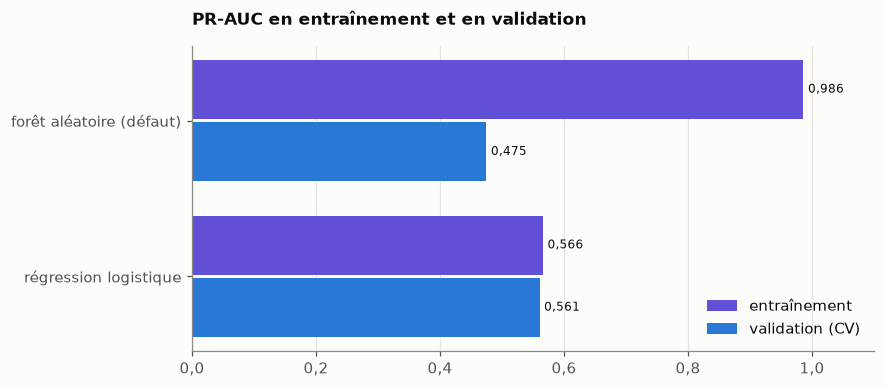

In [6]:
show = ["régression logistique · guide + nos variables", "forêt aléatoire (défaut)"]
gap = pd.DataFrame({
    "PR-AUC entraînement": summary.loc[show, ("pr_auc", "train", "mean")],
    "PR-AUC validation": summary.loc[show, ("pr_auc", "val", "mean")],
})
gap["écart"] = gap["PR-AUC entraînement"] - gap["PR-AUC validation"]
display(gap.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(show))
ax.barh(y + 0.2, gap["PR-AUC entraînement"], 0.38, color=viz.COMPOSITION[1], label="entraînement")
ax.barh(y - 0.2, gap["PR-AUC validation"], 0.38, color=viz.YES, label="validation (CV)")
for yi, (tr, va) in enumerate(zip(gap["PR-AUC entraînement"], gap["PR-AUC validation"])):
    ax.annotate(viz.fr(f"{tr:.3f}"), (tr, yi + 0.2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
    ax.annotate(viz.fr(f"{va:.3f}"), (va, yi - 0.2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(y, ["régression logistique", "forêt aléatoire (défaut)"])
ax.set(title="PR-AUC en entraînement et en validation", xlim=(0, 1.1))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: viz.fr(f"{v:.1f}")))
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
viz.save(fig, "05_entrainement_validation")
plt.show()

**Réponse Q5.3.**
- **Forêt par défaut : variance élevée** (slide 13, « entraînement excellent, validation nettement inférieure »). PR-AUC **0,986** en entraînement contre **0,475** en validation : 51 points d'écart. Avec `min_samples_leaf=1`, chaque arbre pousse jusqu'à isoler presque chaque personne : la forêt **apprend par cœur** les lignes d'entraînement, y compris le bruit (les 7,4 % de lignes aux profils contradictoires, Q2.5). Leviers : régularisation (`min_samples_leaf`, `max_depth`), Q5.5.
- **Régression logistique : biais** (slide 13, « entraînement et validation médiocres, écart faible »). 0,566 contre 0,561 : pas de surapprentissage, mais un plafond. Le modèle est **trop rigide** : une frontière linéaire, des effets additifs, alors que l'étape 2 a montré des interactions (téléphone × éducation) et des effets non linéaires (âge). Leviers : modèle plus riche (arbres régularisés, boosting, étape 6), moins de régularisation, meilleures variables. Le bruit irréductible (≥ 2,2 % d'erreurs, Q2.5) limite aussi tous les modèles.

### Q5.4 · Courbes d'apprentissage

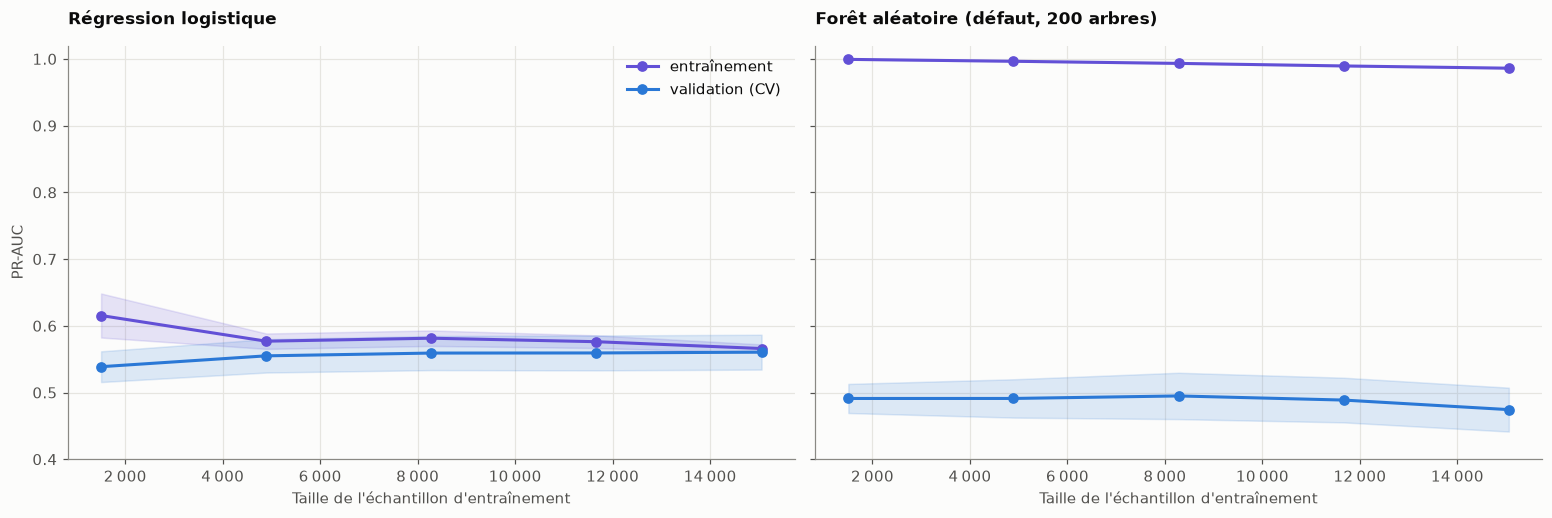

Régression logistique             \
                               entraînement validation   
lignes d'entraînement                                    
1505                                  0.615      0.539   
4892                                  0.577      0.555   
8280                                  0.581      0.559   
11667                                 0.576      0.559   
15055                                 0.566      0.560   

                      Forêt aléatoire (défaut, 200 arbres)             
                                              entraînement validation  
lignes d'entraînement                                                  
1505                                                 0.999      0.491  
4892                                                 0.996      0.491  
8280                                                 0.993      0.495  
11667                                                0.989      0.489  
15055                                                0.986      0.474

In [7]:
curves = {}
for name, model in {
    "Régression logistique": models["régression logistique · guide + nos variables"],
    "Forêt aléatoire (défaut, 200 arbres)": pipe(RandomForestClassifier(n_estimators=200,
                                                 random_state=config.RANDOM_STATE), scale=False),
}.items():
    curves[name] = learning_curve(model, X_train, y_train, cv=CV, scoring="average_precision",
                                  train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True, layout="constrained")
for ax, (name, (sizes, tr, va)) in zip(axes, curves.items()):
    for scores, label, color in [(tr, "entraînement", viz.COMPOSITION[1]), (va, "validation (CV)", viz.YES)]:
        ax.plot(sizes, scores.mean(1), "o-", color=color, lw=2, label=label)
        ax.fill_between(sizes, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15)
    ax.set(title=name, xlabel="Taille de l'échantillon d'entraînement", ylim=(0.4, 1.02))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: viz.fmt_int(v)))
axes[0].set_ylabel("PR-AUC")
axes[0].legend(loc="upper right")
viz.save(fig, "05_courbes_apprentissage")
plt.show()

pd.concat({name: pd.DataFrame({"entraînement": tr.mean(1), "validation": va.mean(1)}, index=sizes)
           for name, (sizes, tr, va) in curves.items()}, axis=1).rename_axis("lignes d'entraînement").round(3)

**Réponse Q5.4.**
- **Régression logistique : non, plus de données n'aiderait pas.** Les deux courbes se rejoignent vers **0,56–0,57** (entraînement 0,615 → 0,566, validation 0,539 → 0,560) et la validation est déjà plate au-delà de 8 000 lignes. C'est le profil « biais élevé » de la slide 12 : le modèle a appris tout ce qu'une frontière linéaire peut apprendre.
- **Forêt par défaut : en principe oui, en pratique très peu.** L'écart énorme entre les courbes (entraînement ≈ 0,99) est le profil « variance élevée » de la slide 12, pour lequel plus de données aide. Mais ici la validation reste **plate autour de 0,49** de 1 500 à 15 000 lignes : la forêt non régularisée mémorise le bruit, et plus de données du même type ne fait qu'ajouter du bruit à mémoriser. Le remède efficace est la **régularisation** (Q5.5), pas la collecte.
- **Conclusion** : collecter plus de lignes avec les **mêmes variables** n'est pas la priorité. Ce qui pourrait aider, ce sont de **nouvelles variables** (revenu, distance à une agence…), qui réduiraient le bruit irréductible.

### Q5.5 · Courbe de validation de `min_samples_leaf`

,entraînement,validation,écart-type validation
min_samples_leaf,,,
1,0.9861,0.4741,0.0326
2,0.8404,0.5514,0.0335
5,0.7028,0.5703,0.0314
10,0.6506,0.5725,0.0300
20,0.6157,0.5707,0.0312
50,0.5839,0.5627,0.0297


,règle d'une erreur-type
meilleure valeur,10.000000
meilleur score,0.572478
erreur-type,0.013395
seuil (meilleur − SE),0.559083
valeur retenue (1 SE),50.000000


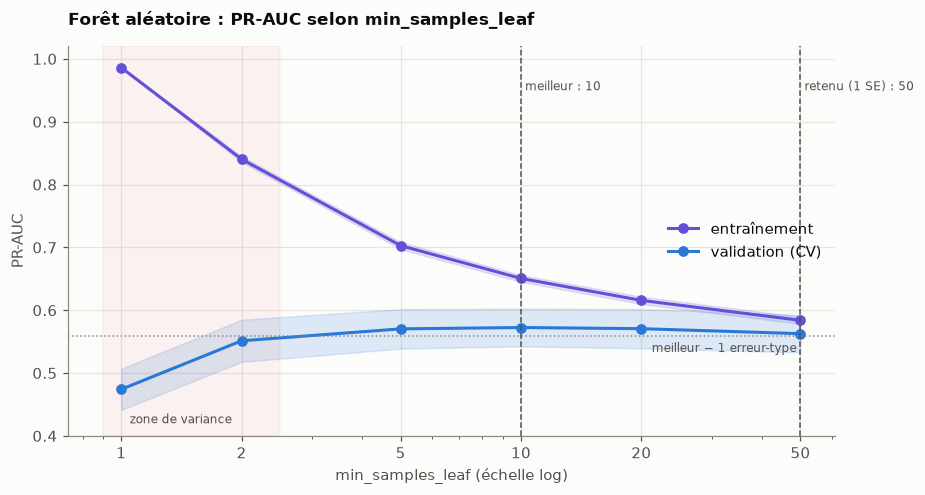

In [8]:
leaf = [1, 2, 5, 10, 20, 50]
rf = pipe(RandomForestClassifier(n_estimators=200, random_state=config.RANDOM_STATE), scale=False)
tr, va = validation_curve(rf, X_train, y_train, cv=CV, scoring="average_precision",
                          param_name="randomforestclassifier__min_samples_leaf", param_range=leaf, n_jobs=-1)
rule = one_standard_error(leaf, va.mean(1), va.std(1))
display(pd.DataFrame({"entraînement": tr.mean(1), "validation": va.mean(1), "écart-type validation": va.std(1)},
                     index=pd.Index(leaf, name="min_samples_leaf")).round(4))
display(pd.Series(rule).to_frame("règle d'une erreur-type"))

fig, ax = plt.subplots(figsize=(9, 4.6))
for scores, label, color in [(tr, "entraînement", viz.COMPOSITION[1]), (va, "validation (CV)", viz.YES)]:
    ax.plot(leaf, scores.mean(1), "o-", color=color, lw=2, label=label)
    ax.fill_between(leaf, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15)
ax.axhline(rule["seuil (meilleur − SE)"], color=viz.INK_3, ls=":", lw=1)
ax.annotate("meilleur − 1 erreur-type ", (leaf[-1], rule["seuil (meilleur − SE)"]), xytext=(0, -4),
            textcoords="offset points", ha="right", va="top", fontsize=8, color=viz.INK_2)
for value, text in [(rule["meilleure valeur"], "meilleur"), (rule["valeur retenue (1 SE)"], "retenu (1 SE)")]:
    ax.axvline(value, color=viz.INK_2, ls="--", lw=1)
    ax.annotate(f" {text} : {value}", (value, 0.95), fontsize=8, color=viz.INK_2)
ax.axvspan(0.9, 2.5, color=viz.SERIES[7], alpha=0.06)
ax.annotate("zone de variance", (1.05, 0.42), fontsize=8, color=viz.INK_2)
ax.set(xscale="log", xticks=leaf, xticklabels=leaf, ylim=(0.4, 1.02),
       title="Forêt aléatoire : PR-AUC selon min_samples_leaf", xlabel="min_samples_leaf (échelle log)", ylabel="PR-AUC")
ax.legend(loc="center right")
viz.save(fig, "05_courbe_validation_min_samples_leaf")
plt.show()

**Réponse Q5.5.**
- **Zone de variance** (`min_samples_leaf` = 1 ou 2) : entraînement 0,986 puis 0,840, validation 0,474 puis 0,551. Les feuilles minuscules collent aux données d'entraînement.
- **Zone de bon compromis** (5 à 20) : la validation culmine à **0,5725 pour 10** (0,570 pour 5 et 20), et l'écart entraînement–validation se resserre (0,650 contre 0,573 à 10).
- **Vers le biais** (50) : entraînement 0,584 et validation 0,563 se rapprochent ; le modèle devient plus rigide et la validation commence à baisser. Au-delà, on retrouverait le profil de la régression logistique.

**Règle d'une erreur-type (slide 52).** Meilleur score 0,5725 (10), erreur-type = 0,030 / √5 = **0,0134**, seuil 0,559. Toutes les valeurs de 5 à 50 sont au-dessus ; la plus simple est la plus **grande** (feuilles plus grosses, arbres plus courts) : on retient **`min_samples_leaf = 50`** (validation 0,563). L'écart avec le meilleur (0,010) est inférieur à une erreur-type : rien ne prouve que 10 soit vraiment meilleur, et 50 donne un modèle plus stable. Ce choix est fait sur la **validation croisée**, jamais sur le test.

**Pourquoi une régularisation (slide 15) ?** `min_samples_leaf` impose un **effectif minimal dans chaque feuille** : l'arbre ne peut plus créer une feuille pour une ou deux personnes, donc il ne peut plus suivre le bruit. Comme λ en régression ridge, ce bouton **augmente le biais et réduit la variance** : petites valeurs = modèle flexible, grandes valeurs = modèle rigide. La courbe en est l'illustration directe.

Régularisée, la forêt passe de 0,475 à 0,56–0,57 et rattrape la régression logistique (comparaison ci-dessous).

In [9]:
# Forêt régularisée contre modèle de base, sur les mêmes plis
reg = {}
for leaf_value in [10, 50]:
    model = pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf_value,
                                        random_state=config.RANDOM_STATE), scale=False)
    reg[leaf_value] = evaluate_cv(model, X_train, y_train, name=f"forêt · min_samples_leaf={leaf_value}")
base = results["régression logistique · guide + nos variables"]
display(format_summary(pd.DataFrame([summary.loc["régression logistique · guide + nos variables"]] + [r[0] for r in reg.values()]),
                       metrics=["pr_auc", "roc_auc", "brier", "logloss", "recall_t", "cost_t"]))
pd.DataFrame({f"forêt {k} − régression logistique": paired_difference(base, r[1]) for k, r in reg.items()}).T.round(4)

,pr_auc,roc_auc,brier,logloss,recall_t,cost_t,temps (s)
régression logistique · guide + nos variables,0.561 ± 0.026,0.849 ± 0.010,0.087 ± 0.003,0.292 ± 0.009,0.852 ± 0.011,0.259 ± 0.006,0.22
forêt · min_samples_leaf=10,0.573 ± 0.031,0.858 ± 0.012,0.086 ± 0.003,0.286 ± 0.010,0.866 ± 0.021,0.250 ± 0.014,2.55
forêt · min_samples_leaf=50,0.562 ± 0.030,0.853 ± 0.012,0.088 ± 0.003,0.292 ± 0.009,0.877 ± 0.025,0.253 ± 0.016,2.37


,moyenne A,moyenne B,écart-type A,différence moyenne B − A,écart-type des différences,erreur-type des différences,plis où B > A,plis
forêt 10 − régression logistique,0.5605,0.5733,0.0261,0.0128,0.0088,0.0044,4.0,5.0
forêt 50 − régression logistique,0.5605,0.5624,0.0261,0.0019,0.0067,0.0034,3.0,5.0


**Lecture.** Sur les mêmes plis :
- **Forêt `min_samples_leaf=10`** : PR-AUC **0,573 ± 0,031**, soit **+0,013** par rapport à la régression logistique, meilleure dans 4 plis sur 5 (erreur-type de la différence appariée 0,004). Elle est aussi un peu meilleure en log-loss (0,286 contre 0,292) et en coût (0,250 contre 0,259 USD par personne). C'est un **gain réel mais modeste** : il dépasse l'erreur-type de la comparaison appariée, mais reste **inférieur à l'écart-type des scores** (0,026), notre règle pour déclarer un modèle meilleur.
- **Forêt `min_samples_leaf=50`** (choix de la règle d'une erreur-type) : +0,002, équivalente à la régression logistique.
- La règle d'une erreur-type, calculée avec l'écart-type des scores (non apparié), est **prudente** : elle préfère le modèle le plus simple tant que l'écart n'est pas net. Ici, la forêt la plus simple rejoint justement le modèle de base.

**Synthèse de l'étape 5.**

| Modèle | Diagnostic | PR-AUC (validation) |
|---|---|---|
| Plancher | — | 0,141 |
| Régression logistique (modèle de base) | **biais** : train ≈ validation, plafond ≈ 0,56 | **0,561 ± 0,026** |
| Forêt par défaut | **variance** : 0,986 en train, 0,475 en validation | 0,475 ± 0,034 |
| Forêt régularisée (`min_samples_leaf=10`) | bon compromis | 0,573 ± 0,031 (+0,013) |
| Forêt régularisée (`min_samples_leaf=50`, règle 1 SE) | vers le biais | 0,562 ± 0,030 |

- Les variables du guide apportent +0,002 (réel mais négligeable), les nôtres rien.
- Plus de données avec les mêmes variables n'aiderait aucun des deux modèles.
- Pour l'étape 6 : la forêt de référence est la forêt **régularisée**, et la question est de savoir si le boosting, qui réduit le **biais**, bat le modèle de base de plus d'un écart-type.

## Étape 6 · Méthodes d'ensemble

On compare **sur les mêmes plis** (`CV`) la forêt réglée à l'étape 5 et quatre boostings : HistGradientBoosting, XGBoost, LightGBM et CatBoost, tous avec leurs **réglages par défaut**.

Par rapport au guide, trois ajouts, pour pouvoir répondre précisément aux questions :
- le **modèle de base** (régression logistique), car tout se juge par rapport à lui ;
- les **deux forêts** de l'étape 5 : `min_samples_leaf=10` (meilleure validation) et `min_samples_leaf=50` (règle d'une erreur-type) ;
- **chaque boosting en one-hot et en natif** (étape 3, `encoding`), pour séparer l'effet de l'encodage de celui de l'algorithme (Q6.4). CatBoost natif passe par `pipe(..., encoding="native_str")` : mêmes variables et même traitement des modalités rares (Q2.6) que les autres modèles ; le guide le donne « sans pipeline », sur les colonnes brutes.

Chaque modèle tourne sur **un seul cœur** (`n_jobs=1`, `thread_count=1`) et la validation croisée parallélise les plis : les temps d'entraînement sont comparables entre modèles.

In [10]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier

from financial_inclusion_africa.features import catboost_cat_features

RS = config.RANDOM_STATE
ensembles = {
    "Régression logistique (modèle de base)": pipe(LogisticRegression(max_iter=2000)),
    "Random Forest · leaf=50 (1 SE)": pipe(RandomForestClassifier(300, min_samples_leaf=50, random_state=RS), scale=False),
    "Random Forest · leaf=10": pipe(RandomForestClassifier(300, min_samples_leaf=10, random_state=RS), scale=False),
    "HistGB · one-hot": pipe(HistGradientBoostingClassifier(random_state=RS), scale=False),
    "HistGB · natif": pipe(HistGradientBoostingClassifier(random_state=RS), encoding="native"),
    "XGBoost · one-hot": pipe(XGBClassifier(random_state=RS, n_jobs=1), scale=False),
    "XGBoost · natif": pipe(XGBClassifier(random_state=RS, n_jobs=1, enable_categorical=True), encoding="native"),
    "LightGBM · one-hot": pipe(LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1), scale=False),
    "LightGBM · natif": pipe(LGBMClassifier(random_state=RS, n_jobs=1, verbose=-1), encoding="native"),
    "CatBoost · one-hot": pipe(CatBoostClassifier(random_seed=RS, thread_count=1, verbose=0), scale=False),
    "CatBoost · natif": pipe(CatBoostClassifier(cat_features=catboost_cat_features(), random_seed=RS,
                                                 thread_count=1, verbose=0), encoding="native_str"),
}
rows6, res6 = [], {}
for name, model in ensembles.items():
    row, res6[name] = evaluate_cv(model, X_train, y_train, name=name)
    rows6.append(row)
summary6 = pd.DataFrame(rows6)
BASE = "Régression logistique (modèle de base)"

### Q6.1 · Tableau comparatif sur les mêmes plis

In [11]:
table6 = format_summary(summary6, metrics=["pr_auc", "roc_auc", "brier", "logloss", "recall_t", "cost_t"])
table6.insert(1, "PR-AUC entraînement", summary6[("pr_auc", "train", "mean")].round(3))
table6.insert(2, "écart train − val", (summary6[("pr_auc", "train", "mean")] - summary6[("pr_auc", "val", "mean")]).round(3))
table6.loc[summary6[("pr_auc", "val", "mean")].sort_values(ascending=False).index]

,pr_auc,PR-AUC entraînement,écart train − val,roc_auc,brier,logloss,recall_t,cost_t,temps (s)
CatBoost · natif,0.583 ± 0.027,0.662,0.080,0.863 ± 0.010,0.084 ± 0.003,0.283 ± 0.010,0.846 ± 0.019,0.240 ± 0.013,22.34
HistGB · natif,0.574 ± 0.026,0.669,0.095,0.857 ± 0.011,0.085 ± 0.003,0.286 ± 0.009,0.837 ± 0.015,0.249 ± 0.011,0.36
Random Forest · leaf=10,0.573 ± 0.031,0.651,0.078,0.858 ± 0.012,0.086 ± 0.003,0.286 ± 0.010,0.866 ± 0.021,0.250 ± 0.014,2.57
HistGB · one-hot,0.568 ± 0.030,0.655,0.087,0.857 ± 0.011,0.086 ± 0.003,0.287 ± 0.010,0.841 ± 0.017,0.248 ± 0.012,0.59
LightGBM · one-hot,0.565 ± 0.029,0.708,0.143,0.854 ± 0.012,0.086 ± 0.003,0.289 ± 0.011,0.837 ± 0.018,0.249 ± 0.012,0.30
LightGBM · natif,0.564 ± 0.023,0.709,0.146,0.854 ± 0.010,0.086 ± 0.003,0.290 ± 0.010,0.828 ± 0.012,0.252 ± 0.008,0.24
CatBoost · one-hot,0.564 ± 0.028,0.748,0.184,0.857 ± 0.010,0.086 ± 0.003,0.289 ± 0.010,0.840 ± 0.016,0.244 ± 0.011,4.64
Random Forest · leaf=50 (1 SE),0.562 ± 0.030,0.584,0.022,0.853 ± 0.012,0.088 ± 0.003,0.292 ± 0.009,0.877 ± 0.025,0.253 ± 0.016,2.21
Régression logistique (modèle de base),0.561 ± 0.026,0.566,0.005,0.849 ± 0.010,0.087 ± 0.003,0.292 ± 0.009,0.852 ± 0.011,0.259 ± 0.006,0.24
XGBoost · one-hot,0.540 ± 0.025,0.795,0.255,0.843 ± 0.010,0.090 ± 0.003,0.305 ± 0.011,0.805 ± 0.010,0.264 ± 0.007,1.02


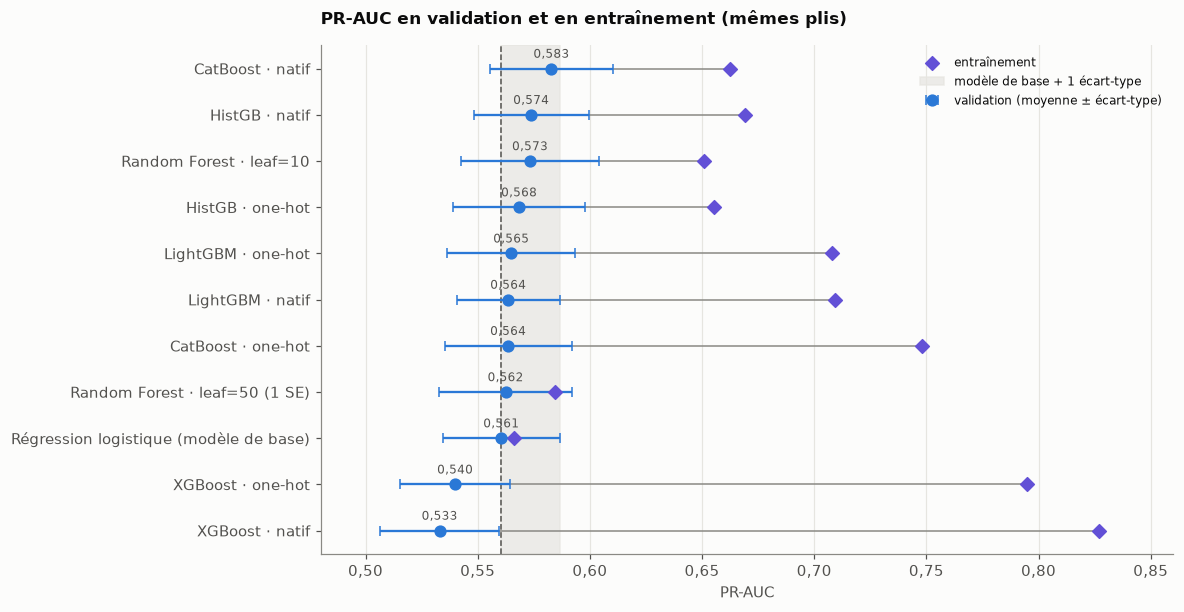

In [12]:
order = summary6[("pr_auc", "val", "mean")].sort_values().index
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(order))
val_mean, val_std = summary6.loc[order, ("pr_auc", "val", "mean")], summary6.loc[order, ("pr_auc", "val", "std")]
train_mean = summary6.loc[order, ("pr_auc", "train", "mean")]
ax.hlines(y, val_mean, train_mean, color=viz.INK_3, lw=1, zorder=1)
ax.errorbar(val_mean, y, xerr=val_std, fmt="o", color=viz.YES, capsize=3, ms=7, label="validation (moyenne ± écart-type)", zorder=3)
ax.scatter(train_mean, y, marker="D", color=viz.COMPOSITION[1], s=40, label="entraînement", zorder=3)
base_mean, base_std = summary6.loc[BASE, ("pr_auc", "val", "mean")], summary6.loc[BASE, ("pr_auc", "val", "std")]
ax.axvline(base_mean, color=viz.INK_2, ls="--", lw=1)
ax.axvspan(base_mean, base_mean + base_std, color=viz.GRID, alpha=0.7, zorder=0, label="modèle de base + 1 écart-type")
for yi, v in zip(y, val_mean):
    ax.annotate(viz.fr(f"{v:.3f}"), (v, yi), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8, color=viz.INK_2)
ax.set_yticks(y, order)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: viz.fr(f"{v:.2f}")))
ax.set(title="PR-AUC en validation et en entraînement (mêmes plis)", xlabel="PR-AUC", xlim=(0.48, 0.86))
ax.legend(loc="upper right", fontsize=8)
ax.grid(axis="y", visible=False)
viz.save(fig, "06_comparaison_ensembles")
plt.show()

**Réponse Q6.1.** (réglages par défaut, validation croisée à 5 plis, temps par pli sur un cœur ; les temps varient légèrement d'une exécution à l'autre)

| Modèle | PR-AUC (val.) | PR-AUC (train) | ROC-AUC | Brier | Coût / pers. | Temps |
|---|---|---|---|---|---|---|
| **CatBoost · natif** | **0,583 ± 0,027** | 0,662 | **0,863** | **0,084** | **0,240** | 22,4 s |
| HistGB · natif | 0,574 ± 0,026 | 0,669 | 0,857 | 0,085 | 0,249 | 0,4 s |
| Random Forest · leaf=10 | 0,573 ± 0,031 | 0,651 | 0,858 | 0,086 | 0,250 | 2,6 s |
| HistGB · one-hot | 0,568 ± 0,030 | 0,655 | 0,857 | 0,086 | 0,248 | 0,6 s |
| LightGBM · one-hot | 0,565 ± 0,029 | 0,708 | 0,854 | 0,086 | 0,249 | 0,3 s |
| LightGBM · natif | 0,564 ± 0,023 | 0,709 | 0,854 | 0,086 | 0,252 | 0,2 s |
| CatBoost · one-hot | 0,564 ± 0,028 | 0,748 | 0,857 | 0,086 | 0,244 | 4,6 s |
| Random Forest · leaf=50 | 0,562 ± 0,030 | 0,584 | 0,853 | 0,088 | 0,253 | 2,3 s |
| *Régression logistique* | *0,561 ± 0,026* | *0,566* | *0,849* | *0,087* | *0,259* | *0,2 s* |
| XGBoost · one-hot | 0,540 ± 0,025 | 0,795 | 0,843 | 0,090 | 0,264 | 1,0 s |
| XGBoost · natif | 0,533 ± 0,027 | 0,827 | 0,838 | 0,091 | 0,270 | 0,9 s |

Les écarts sont **petits** : de 0,533 à 0,583, alors que l'écart-type d'un modèle est d'environ 0,027. Sur ce jeu, les ensembles n'« écrasent » pas la régression logistique comme dans l'exemple de la slide 38 : le bruit irréductible (Q2.5) et des variables pauvres plafonnent tous les modèles.

### Q6.2 · Peut-on désigner un vainqueur ?

In [13]:
paired6 = pd.DataFrame({name: paired_difference(res6[BASE], res6[name]) for name in ensembles if name != BASE}).T
paired6 = paired6.sort_values("différence moyenne B − A", ascending=False)
display(paired6[["moyenne B", "différence moyenne B − A", "erreur-type des différences", "plis où B > A"]]
        .rename(columns={"moyenne B": "PR-AUC", "différence moyenne B − A": "écart au modèle de base"}).round(4))

# Le meilleur contre ses poursuivants immédiats
best = paired6.index[0]
pd.DataFrame({f"{best} − {other}": paired_difference(res6[other], res6[best]) for other in paired6.index[1:4]}).T[
    ["différence moyenne B − A", "erreur-type des différences", "plis où B > A"]].round(4)

,PR-AUC,écart au modèle de base,erreur-type des différences,plis où B > A
CatBoost · natif,0.5829,0.0223,0.0046,5.0
HistGB · natif,0.5738,0.0133,0.0045,4.0
Random Forest · leaf=10,0.5733,0.0128,0.0044,4.0
HistGB · one-hot,0.5685,0.0080,0.0038,3.0
LightGBM · one-hot,0.5650,0.0044,0.0051,3.0
LightGBM · natif,0.5636,0.0031,0.0057,4.0
CatBoost · one-hot,0.5636,0.0031,0.0087,3.0
Random Forest · leaf=50 (1 SE),0.5624,0.0019,0.0034,3.0
XGBoost · one-hot,0.5399,-0.0206,0.0066,0.0
XGBoost · natif,0.5330,-0.0275,0.0096,0.0


,différence moyenne B − A,erreur-type des différences,plis où B > A
CatBoost · natif − HistGB · natif,0.0090,0.0023,5.0
CatBoost · natif − Random Forest · leaf=10,0.0095,0.0020,5.0
CatBoost · natif − HistGB · one-hot,0.0144,0.0032,5.0


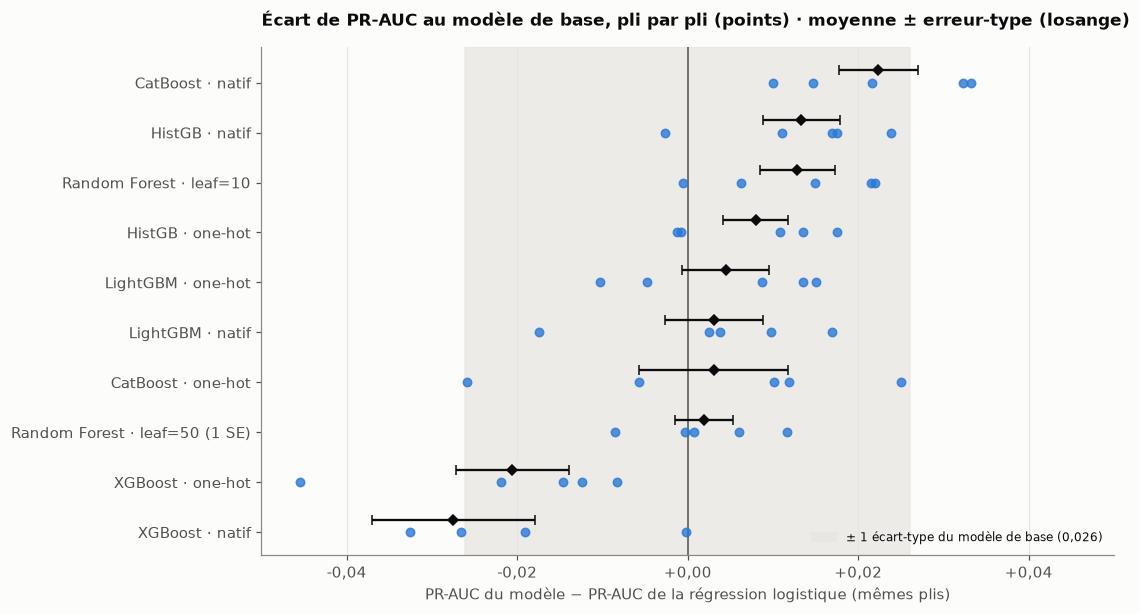

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
names6 = list(paired6.index)[::-1]
for i, name in enumerate(names6):
    d = fold_scores(res6[name])["pr_auc"] - fold_scores(res6[BASE])["pr_auc"]
    ax.scatter(d, [i] * len(d), color=viz.YES, s=30, alpha=0.8, zorder=3)
    ax.errorbar(d.mean(), i + 0.25, xerr=d.std(ddof=1) / np.sqrt(len(d)), fmt="D", color=viz.INK, ms=5, capsize=3, zorder=4)
ax.axvline(0, color=viz.INK_2, lw=1)
ax.axvspan(-base_std, base_std, color=viz.GRID, alpha=0.7, zorder=0,
           label=f"± 1 écart-type du modèle de base ({viz.fr(f'{base_std:.3f}')})")
ax.set_yticks(range(len(names6)), names6)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: viz.fr(f"{v:+.2f}")))
ax.set(title="Écart de PR-AUC au modèle de base, pli par pli (points) · moyenne ± erreur-type (losange)",
       xlabel="PR-AUC du modèle − PR-AUC de la régression logistique (mêmes plis)", xlim=(-0.05, 0.05))
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
viz.save(fig, "06_ecarts_au_modele_de_base")
plt.show()

**Réponse Q6.2.** **Non, pas de vainqueur net.**

- **Écarts contre écarts-types.** Le meilleur, CatBoost natif (0,583), dépasse le modèle de base de **+0,022**, et les suivants (HistGB natif, forêt leaf=10) de +0,013. Tous ces écarts restent **sous un écart-type** (0,026) : selon notre règle, aucun modèle ne bat nettement la régression logistique. Entre eux, les écarts sont encore plus faibles : CatBoost natif ne devance HistGB natif et la forêt leaf=10 que de +0,009, mais **dans les 5 plis** (erreur-type 0,002) : une avance faible mais régulière.
- **Pli par pli (slide 38).** La comparaison appariée est plus fine : CatBoost natif fait mieux que le modèle de base dans **les 5 plis**, avec une erreur-type de la différence de 0,005 ; son avance est donc **régulière**, pas un accident d'un pli. HistGB natif et la forêt leaf=10 gagnent 4 plis sur 5. XGBoost par défaut perd dans les 5 plis.
- **Comparaisons multiples (slide 24).** Nous avons comparé 11 modèles : le meilleur score est **flatté** par la sélection, comme le « meilleur » de 100 modèles aléatoires. Les 0,583 de CatBoost sont une estimation optimiste ; seule la mesure finale sur le test, faite une fois (étape 10), dira ce qu'il vaut vraiment.

**Conclusion** : un petit groupe de modèles (CatBoost natif, HistGB natif, forêt régularisée) fait un peu et régulièrement mieux que le modèle de base, sans écart décisif. Le choix se fera aussi sur le temps, la calibration et la marge de réglage (Q6.5).

### Q6.3 · Qui surapprend avec ses réglages par défaut ?

In [15]:
gap6 = pd.DataFrame({
    "PR-AUC entraînement": summary6[("pr_auc", "train", "mean")],
    "PR-AUC validation": summary6[("pr_auc", "val", "mean")],
})
gap6["écart"] = gap6["PR-AUC entraînement"] - gap6["PR-AUC validation"]
gap6.sort_values("écart", ascending=False).round(3)

,PR-AUC entraînement,PR-AUC validation,écart
XGBoost · natif,0.827,0.533,0.294
XGBoost · one-hot,0.795,0.540,0.255
CatBoost · one-hot,0.748,0.564,0.184
LightGBM · natif,0.709,0.564,0.146
LightGBM · one-hot,0.708,0.565,0.143
HistGB · natif,0.669,0.574,0.095
HistGB · one-hot,0.655,0.568,0.087
CatBoost · natif,0.662,0.583,0.080
Random Forest · leaf=10,0.651,0.573,0.078
Random Forest · leaf=50 (1 SE),0.584,0.562,0.022


**Réponse Q6.3.** On le voit à l'**écart entre PR-AUC d'entraînement et de validation** (tableau ci-dessus, segments gris de la figure de Q6.1).

- **XGBoost surapprend nettement** : 0,795–0,827 en entraînement contre 0,533–0,540 en validation (écart ≈ 0,26–0,29), et c'est le seul modèle **sous** le modèle de base. Ses réglages par défaut sont agressifs pour un petit jeu bruité : pas d'apprentissage 0,3, arbres de profondeur 6, aucun arrêt anticipé.
- **LightGBM et CatBoost one-hot surapprennent modérément** (écart ≈ 0,14–0,18) : LightGBM pousse ses arbres feuille par feuille (31 feuilles), ce qui « surapprend sur petits jeux » (slide 35).
- **HistGB, CatBoost natif et la forêt leaf=10** : écart ≈ 0,08–0,10, raisonnable. CatBoost a de bons réglages par défaut (slide 35) : 1 000 arbres symétriques, pas d'apprentissage automatique, régularisation L2.
- **Forêt leaf=50 et régression logistique** : écart ≈ 0,02, pas de surapprentissage.

**Lien avec bagging et boosting (slides 32–34).** Le **bagging** (forêt) moyenne des arbres profonds de **faible biais mais forte variance** : il réduit la variance, mais une forêt dont les feuilles ne contiennent qu'une personne garde trop de variance (étape 5 : 0,986 contre 0,475). Le **boosting** additionne des arbres peu profonds, chacun corrigeant les erreurs des précédents : il réduit le **biais**, mais à force d'ajouter des arbres il finit par corriger le bruit, d'où le surapprentissage de XGBoost. Le remède est l'**arrêt anticipé** et un pas plus petit (slide 34), objet de l'étape 7. Ici, le gain de biais du boosting reste modeste : la régression logistique n'était pas si loin du plafond imposé par le bruit.

### Q6.4 · CatBoost avec catégories natives contre one-hot

PR-AUC         temps (s)        
          natif one-hot     natif one-hot
CatBoost  0.583   0.564    22.340   4.641
HistGB    0.574   0.568     0.362   0.591
LightGBM  0.564   0.565     0.241   0.304
XGBoost   0.533   0.540     0.930   1.022

,natif − one-hot,erreur-type des différences,plis où B > A
HistGB,0.0054,0.0029,3.0
XGBoost,-0.0069,0.0039,1.0
LightGBM,-0.0013,0.0035,3.0
CatBoost,0.0193,0.0048,5.0


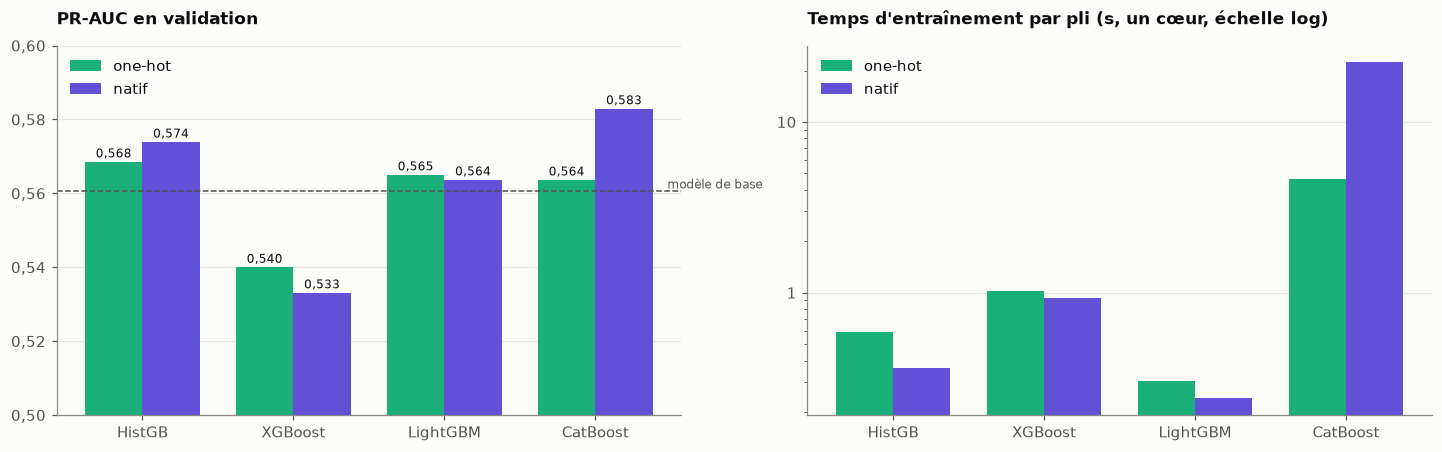

In [16]:
algos = ["HistGB", "XGBoost", "LightGBM", "CatBoost"]
enc = pd.DataFrame({
    (a, e): {"PR-AUC": summary6.loc[f"{a} · {e}", ("pr_auc", "val", "mean")],
             "temps (s)": summary6.loc[f"{a} · {e}", ("fit_time", "", "mean")]}
    for a in algos for e in ["one-hot", "natif"]
}).T
enc_gain = pd.DataFrame({a: paired_difference(res6[f"{a} · one-hot"], res6[f"{a} · natif"]) for a in algos}).T
display(enc.unstack().round(3))
display(enc_gain[["différence moyenne B − A", "erreur-type des différences", "plis où B > A"]]
        .rename(columns={"différence moyenne B − A": "natif − one-hot"}).round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
x = np.arange(len(algos))
for k, (e, color) in enumerate([("one-hot", viz.COMPOSITION[0]), ("natif", viz.COMPOSITION[1])]):
    pr = [enc.loc[(a, e), "PR-AUC"] for a in algos]
    tm = [enc.loc[(a, e), "temps (s)"] for a in algos]
    ax1.bar(x + (k - 0.5) * 0.38, pr, 0.38, color=color, label=e)
    ax2.bar(x + (k - 0.5) * 0.38, tm, 0.38, color=color, label=e)
    for xi, v in zip(x, pr):
        ax1.annotate(viz.fr(f"{v:.3f}"), (xi + (k - 0.5) * 0.38, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
ax1.axhline(base_mean, color=viz.INK_2, ls="--", lw=1)
ax1.annotate(" modèle de base", (3.45, base_mean), va="bottom", fontsize=8, color=viz.INK_2)
ax1.set(title="PR-AUC en validation", ylim=(0.5, 0.6))
ax2.set(title="Temps d'entraînement par pli (s, un cœur, échelle log)", yscale="log")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: viz.fr(f"{v:.2f}")))
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: viz.fr(f"{v:g}")))
for ax in (ax1, ax2):
    ax.set_xticks(x, algos)
    ax.legend(loc="upper left")
    ax.grid(axis="x", visible=False)
viz.save(fig, "06_encodage_natif_onehot")
plt.show()

**Réponse Q6.4.**
- **Performance** : CatBoost natif (**0,583**) fait mieux que tous les modèles en one-hot (0,540 à 0,568) et que **CatBoost lui-même en one-hot** (0,564) : **+0,019**, dans les **5 plis** (erreur-type 0,005). C'est donc bien son **traitement des catégories** qui fait la différence, pas seulement l'algorithme. Pour les autres boostings, l'encodage natif n'apporte rien de net (HistGB +0,006, LightGBM −0,001, XGBoost −0,007).
- **Temps** : CatBoost natif est de loin le plus lent, **22 s par pli** sur un cœur, contre 4,6 s en one-hot et moins d'une seconde pour HistGB et LightGBM (slide 35 : « entraînement plus lent »). L'écart vient du calcul des statistiques de cible par modalité, refait pour chaque permutation.
- **Avantage théorique (slide 35)** : CatBoost remplace chaque modalité par une **statistique de la cible** (la part des personnes qui ont un compte dans cette modalité), mais calculée de façon **ordonnée** : pour une ligne, seules les lignes qui la précèdent dans une permutation aléatoire sont utilisées. La ligne ne voit jamais sa propre cible : **pas de fuite de cible**, contrairement à un encodage par la moyenne naïf. Il combine aussi les modalités entre elles (par exemple pays × emploi), ce qui capte des interactions que le one-hot oblige les arbres à reconstruire coupure par coupure. Avec 8 variables catégorielles et des interactions fortes (étape 2), c'est exactement le terrain où cet avantage compte.

### Q6.5 · Un ou deux modèles candidats pour la suite

In [17]:
# Rapport de classification complet au seuil t* (prédictions hors pli) pour les deux candidats
for name in ["CatBoost · natif", "LightGBM · natif"]:
    oof = cross_val_predict(ensembles[name], X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    print(f"── {name} · seuil t* = {T_STAR:.3f}\n{full_classification_report(y_train, oof, T_STAR)}")

── CatBoost · natif · seuil t* = 0.091
              precision    recall  f1-score   support

      No (0)     0.9648    0.6941    0.8074     16169
     Yes (1)     0.3118    0.8457    0.4556      2650

    accuracy                         0.7154     18819
   macro avg     0.6383    0.7699    0.6315     18819
weighted avg     0.8729    0.7154    0.7578     18819



── LightGBM · natif · seuil t* = 0.091
              precision    recall  f1-score   support

      No (0)     0.9611    0.6953    0.8069     16169
     Yes (1)     0.3082    0.8283    0.4492      2650

    accuracy                         0.7140     18819
   macro avg     0.6347    0.7618    0.6281     18819
weighted avg     0.8692    0.7140    0.7565     18819



**Réponse Q6.5.** Nous retenons **deux candidats**, en plus du modèle de base qui reste la référence :

1. **CatBoost natif**, le candidat « performance ».
   - Meilleure PR-AUC (0,583), meilleur Brier (0,084), meilleure log-loss (0,283), coût le plus bas (0,240 USD par personne), et une avance sur le modèle de base dans **les 5 plis**.
   - Surapprentissage modéré avec ses réglages par défaut, probabilités déjà bien placées : un atout pour la banque centrale (étape 8).
   - Prix à payer : **22 s par pli**, ce qui rend une recherche d'hyperparamètres de 40 essais coûteuse (≈ 1 h sur un cœur, quelques minutes en parallèle).
2. **LightGBM natif**, le candidat « réglage ».
   - Performance moyenne par défaut (0,564), mais **le plus rapide** (0,2 s par pli, 100 fois plus vite que CatBoost) : on peut explorer beaucoup d'essais.
   - Il **surapprend** avec ses réglages par défaut (0,71 en entraînement) : il a donc la plus grande marge de progrès par l'optimisation des hyperparamètres (pas plus petit, moins de feuilles, régularisation, arrêt anticipé). C'est aussi le modèle des exemples de l'étape 7 du guide.

**Pourquoi pas les autres ?** HistGB natif (0,574) est un excellent compromis, très proche de LightGBM dans son principe : garder les deux serait redondant. La forêt leaf=10 (0,573) est 10 fois plus lente que HistGB pour le même score. XGBoost par défaut est le seul sous le modèle de base. **Simplicité** : si, après réglage, aucun candidat ne dépasse la régression logistique de plus d'un écart-type, celle-ci reste un choix défendable : plus simple, plus rapide, interprétable (règle d'une erreur-type).

### Synthèse de l'étape 6

- **Pas de vainqueur net** : tous les écarts au modèle de base restent sous un écart-type ; CatBoost natif est devant dans les 5 plis (+0,022).
- **Surapprentissage par défaut** : fort pour XGBoost, modéré pour LightGBM ; à corriger par l'arrêt anticipé et le réglage (étape 7).
- **Catégories natives** : décisives pour CatBoost (+0,019 sur son one-hot), sans effet net ailleurs ; au prix d'un temps d'entraînement 5 fois plus long.
- **Candidats pour l'étape 7** : CatBoost natif (performance) et LightGBM natif (rapidité, marge de réglage) ; la régression logistique reste la référence.